# Frozen MiniLM scam-intent classifier

Original fixed training/validation split, with the same exact-duplicate exclusions
as the TF-IDF baseline. MiniLM remains frozen; only logistic regression is fitted.
Select C and threshold using the original 192 validation examples. Challenge data
and official test text are not loaded or scored in this notebook.

Run on a Colab A100 using the CLI. Upload `outputs/text/minilm_inputs.zip` to
`/content/minilm_inputs.zip` first. The reference archive contains the frozen
TF-IDF model and split/fold metadata, **no challenge transcripts**. The encoder
actually computes on CUDA; logistic regression uses CPU.

Tokenizer/model revision is pinned. Inputs are sliced at 254 content wordpieces,
leaving two special tokens within a 256-token sequence. Encode each chunk with
attention-mask mean pooling and L2 normalization; average chunk vectors equally
and L2-normalize the dialogue mean. No chunks cross dialogue boundaries.

This follows the [official model-card mean-pooling recipe](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
extended with a fixed chunk-averaging policy. Chunking is not selected using
challenge performance. Embedding cache keys include ordered IDs, raw text hashes,
the model revision, and pooling/chunking recipe. Cache reuse is verified.


In [2]:
import os
from pathlib import Path
import subprocess
import sys

# Keep the default for the requested remote run. Set the environment variable to 0
# only for an explicitly labelled local smoke run.
REQUIRE_COLAB_A100 = os.environ.get("SCAM_REQUIRE_COLAB_A100", "1") == "1"
try:
    gpu = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], text=True
    ).strip()
except (OSError, subprocess.SubprocessError):
    gpu = "unavailable"
is_colab = bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
print({"Colab runtime": is_colab, "GPU": gpu, "Python": sys.version})
if REQUIRE_COLAB_A100:
    assert is_colab and "A100" in gpu, "Connect a Colab A100 kernel before running."

# Public model: avoid optional transfer-backend and credential discovery paths.
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"


{'Colab runtime': True, 'GPU': 'NVIDIA A100-SXM4-40GB, 40960 MiB', 'Python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]'}


## Dependencies and remote paths

In [3]:
requirements = "# Remote MiniLM environment; keep separate from shared project setup.\nnumpy==2.2.6\npandas==2.3.3\nscipy==1.18.1\nscikit-learn==1.7.2\nmatplotlib==3.10.7\njoblib==1.6.0\nnbformat==5.10.4\nnbclient==0.10.2\nipykernel==7.0.1\ntransformers==4.57.1\nhuggingface-hub==0.35.3\ntokenizers==0.22.1\nsafetensors==0.6.2\n# Use the Colab runtime's CUDA-enabled PyTorch; record its exact version.\n"
if is_colab:
    import importlib.metadata
    requested = [line for line in requirements.splitlines() if line and not line.startswith("#")]
    mismatches = []
    for item in requested:
        name, expected = item.split("==")
        try:
            actual = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            actual = None
        if actual != expected:
            mismatches.append(item)
    if mismatches:
        loaded_before_install = [name for name in ("numpy", "pandas", "scipy", "sklearn", "matplotlib") if name in sys.modules]
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *requested], check=True)
        if loaded_before_install:
            raise RuntimeError("Dependencies installed. Restart the kernel and Run All before importing numerical libraries.")

ROOT = Path.cwd()
if not is_colab:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), ROOT)
DATA_DIR = ROOT / "data/scam_dialogue"
OUTPUT_DIR = ROOT / "outputs/text/minilm"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Artifacts:", OUTPUT_DIR)


Artifacts: /content/outputs/text/minilm


## Frozen references and implementation

In [4]:
import hashlib
import zipfile

inputs_zip = Path("/content/minilm_inputs.zip") if is_colab else ROOT / "outputs/text/minilm_inputs.zip"
assert hashlib.sha256(inputs_zip.read_bytes()).hexdigest() == '9c3f454e699bbdbdbe9fbecafdf33e89418f5686631bf5b31ba2bcb9a6821d92'
INPUT_DIR = ROOT / "outputs/text/minilm_inputs"
INPUT_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(inputs_zip) as package:
    assert all(not Path(name).is_absolute() and ".." not in Path(name).parts for name in package.namelist())
    package.extractall(INPUT_DIR)

CODE_DIR = ROOT / "outputs/text/minilm_code"
MODULE_DIR = CODE_DIR / "src/text"
MODULE_DIR.mkdir(parents=True, exist_ok=True)
(MODULE_DIR.parent / "__init__.py").write_text("")
(MODULE_DIR / "__init__.py").write_text("")
sources = {'baseline': '"""Reproducible scam-text audit and train-only TF-IDF baseline.\n\nRun from the repository root: python -m src.text.baseline\nOnly validation metrics are computed at this milestone; test remains sealed.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport importlib.metadata\nimport json\nimport platform\nimport re\nimport subprocess\nimport sys\nimport unicodedata\nfrom pathlib import Path\nfrom urllib.request import urlopen\n\nimport joblib\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom sklearn.base import clone\nfrom sklearn.feature_extraction.text import HashingVectorizer, TfidfVectorizer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (\n    ConfusionMatrixDisplay, confusion_matrix, f1_score,\n    precision_score, recall_score,\n)\nfrom sklearn.model_selection import StratifiedGroupKFold, train_test_split\nfrom sklearn.pipeline import Pipeline\n\nREVISION = "321b961b5ae353e19ed479b960658dcd223d5e06"\nDATASET = "BothBosu/scam-dialogue"\nSOURCE_SHA256 = {\n    "scam-dialogue_train.csv": "cda5d42d15fd341208a25466d9ea279de905a640bd153f67b5c29743520f96f8",\n    "scam-dialogue_test.csv": "17a9e52e90d893541d76dbb4588cb75b1a66ef2474ef2619d56feff5b8d5aec0",\n}\nSEED = 42\nNEAR_THRESHOLD = 0.90\nTURN = re.compile(r"\\b(?:caller|receiver)\\s*:", re.IGNORECASE)\n\n\ndef sha256(value: str | bytes) -> str:\n    return hashlib.sha256(value.encode("utf-8") if isinstance(value, str) else value).hexdigest()\n\n\ndef normalized(text: str) -> str:\n    return " ".join(unicodedata.normalize("NFKC", text).casefold().split())\n\n\ndef turns(text: str) -> list[str]:\n    starts = [m.start() for m in TURN.finditer(text)]\n    if not starts:\n        return [text]\n    starts[0] = 0  # Preserve any preamble.\n    return [text[a:b].strip() for a, b in zip(starts, starts[1:] + [len(text)])]\n\n\ndef prefix(text: str, fraction: float) -> str:\n    items = turns(text)\n    return " ".join(items[:max(1, int(np.ceil(len(items) * fraction)))])\n\n\ndef write_json(path: Path, value) -> None:\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\\n", encoding="utf-8")\n\n\ndef runtime_info(require_a100: bool = False) -> dict:\n    try:\n        result = subprocess.run(\n            ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],\n            capture_output=True, text=True, timeout=15, check=True,\n        )\n        gpu = result.stdout.strip()\n    except (OSError, subprocess.SubprocessError):\n        gpu = "unavailable"\n    # This detects the remote runtime, including a VS Code Colab kernel.\n    import os\n    colab = bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))\n    info = {\n        "python": sys.version, "platform": platform.platform(), "gpu": gpu,\n        "colab_runtime": colab,\n        "classifier_compute": "CPU (scikit-learn TF-IDF/logistic regression)",\n        "versions": {name: importlib.metadata.version(name) for name in\n                     ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib"]},\n    }\n    if require_a100 and not (colab and "A100" in gpu):\n        raise RuntimeError(f"A Colab A100 runtime is required; observed: {info}")\n    return info\n\n\ndef load_data(data_dir: Path, output_dir: Path) -> pd.DataFrame:\n    data_dir.mkdir(parents=True, exist_ok=True)\n    frames, files = [], {}\n    for source, count in [("train", 1280), ("test", 320)]:\n        name = f"scam-dialogue_{source}.csv"\n        # Cache names are revision-scoped so a different snapshot cannot be reused silently.\n        path = data_dir / REVISION / name\n        path.parent.mkdir(parents=True, exist_ok=True)\n        if not path.exists():\n            url = f"https://huggingface.co/datasets/{DATASET}/resolve/{REVISION}/{name}"\n            with urlopen(url, timeout=120) as response:\n                payload = response.read()\n            path.write_bytes(payload)\n        files[name] = sha256(path.read_bytes())\n        if files[name] != SOURCE_SHA256[name]:\n            raise ValueError(f"Dataset checksum mismatch: {path}; investigate cache/source before proceeding")\n        frame = pd.read_csv(path, keep_default_na=False)\n        if set(frame.columns) != {"dialogue", "type", "label"} or len(frame) != count:\n            raise ValueError(f"Unexpected schema/count in {name}: {frame.shape}, {frame.columns}")\n        if not frame.label.isin([0, 1]).all():\n            raise ValueError("Labels must be 0/1")\n        frame["source_split"] = source\n        frame["source_row"] = np.arange(len(frame))  # zero-based CSV data-row ordinal\n        frame["text_sha256"] = frame.dialogue.map(sha256)\n        frame["normalized_sha256"] = frame.dialogue.map(lambda s: sha256(normalized(s)))\n        frame["dialogue_id"] = [f"scam-{source}-{i:04d}-{digest[:16]}"\n                                for i, digest in zip(frame.source_row, frame.text_sha256)]\n        frame["split"] = source\n        frames.append(frame)\n    data = pd.concat(frames, ignore_index=True)\n    train_indices = data.index[data.source_split.eq("train")]\n    _, validation = train_test_split(\n        train_indices, test_size=192, random_state=SEED,\n        stratify=data.loc[train_indices, "label"],\n    )\n    data.loc[validation, "split"] = "validation"\n    data["included"] = True\n    data["exclusion_reason"] = ""\n    empty = data.dialogue.str.strip().eq("")\n    if empty[data.split.eq("test")].any():\n        raise ValueError("Missing test text: preserve test and investigate before fitting")\n    data.loc[empty, ["included", "exclusion_reason"]] = [False, "missing_text"]\n    # Preserve test, then validation; remove exact/whitespace/case duplicates from lower-priority pools.\n    # Similarity matches alone NEVER cause exclusions.\n    priority = {"test": 0, "validation": 1, "train": 2}\n    ordered = data.assign(priority=data.split.map(priority)).sort_values(["priority", "source_row"])\n    for _, group in ordered.loc[~empty.reindex(ordered.index)].groupby("normalized_sha256", sort=False):\n        if len(group) < 2:\n            continue\n        if group.label.nunique() != 1:\n            raise ValueError("Conflicting labels in duplicate group; manual review required")\n        keep = group.iloc[0]\n        for index, row in group.iloc[1:].iterrows():\n            if row.split != "test":\n                data.loc[index, ["included", "exclusion_reason"]] = [\n                    False, f"normalized_duplicate_of:{keep.dialogue_id}"]\n    if not data.dialogue_id.is_unique:\n        raise ValueError("ID collision")\n    manifest_cols = ["dialogue_id", "source_split", "source_row", "text_sha256",\n                     "normalized_sha256", "split", "label", "included", "exclusion_reason"]\n    output_dir.mkdir(parents=True, exist_ok=True)\n    manifest_text = data[manifest_cols].to_csv(index=False, lineterminator="\\n")\n    (output_dir / "split_manifest.csv").write_text(manifest_text, encoding="utf-8", newline="")\n    write_json(output_dir / "dataset_provenance.json", {\n        "dataset": DATASET, "revision": REVISION, "file_sha256": files,\n        "seed": SEED, "validation_size": 192, "stratification": "label",\n        "id_rule": "scam-{published_split}-{zero_based_row:04d}-{raw_text_sha256[:16]}",\n    })\n    return data\n\n\ndef audit(data: pd.DataFrame, output_dir: Path) -> dict:\n    lengths = data[["dialogue_id", "split", "label", "type", "included"]].copy()\n    lengths["characters"] = data.dialogue.str.len()\n    lengths["words"] = data.dialogue.str.split().map(len)\n    lengths["turns"] = data.dialogue.map(lambda s: len(turns(s)))\n    lengths.to_csv(output_dir / "dialogue_lengths.csv", index=False)\n    balance = data.groupby(["split", "included", "label", "type"]).size().rename("count").reset_index()\n    balance.to_csv(output_dir / "class_type_counts.csv", index=False)\n    duplicate_rows = data[data.duplicated("normalized_sha256", keep=False)]\n    duplicate_rows.drop(columns="dialogue").to_csv(output_dir / "exact_duplicate_rows.csv", index=False)\n    # Stateless character hashing is an audit instrument only, never a model input.\n    hasher = HashingVectorizer(analyzer="char", ngram_range=(5, 5), n_features=2**18,\n                               alternate_sign=False, lowercase=True, norm="l2")\n    vectors = hasher.transform(data.dialogue.map(normalized))\n    similarity = (vectors @ vectors.T).toarray()\n    upper = np.triu(np.ones(similarity.shape, dtype=bool), 1)\n    cross = data.split.to_numpy()[:, None] != data.split.to_numpy()[None, :]\n    indices = np.argwhere(upper & cross & (similarity >= NEAR_THRESHOLD))\n    records = []\n    for i, j in indices:\n        a, b = data.iloc[i], data.iloc[j]\n        records.append({"id_a": a.dialogue_id, "id_b": b.dialogue_id,\n                        "split_a": a.split, "split_b": b.split,\n                        "similarity": float(similarity[i, j]),\n                        "normalized_exact": a.normalized_sha256 == b.normalized_sha256,\n                        "included_a": bool(a.included), "included_b": bool(b.included)})\n    columns = ["id_a", "id_b", "split_a", "split_b", "similarity", "normalized_exact", "included_a", "included_b"]\n    pairs = pd.DataFrame(records, columns=columns).sort_values("similarity", ascending=False)\n    pairs.to_csv(output_dir / "near_duplicate_candidates.csv", index=False)\n    # Keep full matching text locally for actual human inspection, including the most similar\n    # pair for each split boundary even if no pair clears the candidate threshold.\n    review = pairs.to_dict("records")\n    for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:\n        a = data.index[data.split.eq(left)].to_numpy()\n        b = data.index[data.split.eq(right)].to_numpy()\n        local_i, local_j = np.unravel_index(np.argmax(similarity[np.ix_(a, b)]), (len(a), len(b)))\n        i, j = a[local_i], b[local_j]\n        review.append({"id_a": data.iloc[i].dialogue_id, "id_b": data.iloc[j].dialogue_id,\n                       "similarity": float(similarity[i, j]), "boundary_maximum": f"{left}/{right}"})\n    lookup = data.set_index("dialogue_id")\n    for row in review:\n        row["dialogue_a"] = lookup.loc[row["id_a"], "dialogue"]\n        row["dialogue_b"] = lookup.loc[row["id_b"], "dialogue"]\n    write_json(output_dir / "similarity_review_text.json", review)\n    summary = {\n        "raw_rows": len(data), "missing_text": int(data.dialogue.str.strip().eq("").sum()),\n        "planned_counts": data.split.value_counts().to_dict(),\n        "included_counts": data[data.included].split.value_counts().to_dict(),\n        "excluded_count": int((~data.included).sum()),\n        "raw_exact_duplicate_groups": int(data.groupby("text_sha256").size().gt(1).sum()),\n        "normalized_duplicate_groups": int(data.groupby("normalized_sha256").size().gt(1).sum()),\n        "cross_split_candidates": len(pairs), "candidate_threshold": NEAR_THRESHOLD,\n        "audit_similarity": "cosine of stateless 2^18-bin character 5-gram hashes; collisions possible",\n        "length_summary": lengths[["characters", "words", "turns"]].describe().to_dict(),\n        "exclusion_policy": "Missing text and normalized exact duplicates only; test always retained. No similarity-only exclusions.",\n        "wordpiece_lengths": "Deferred to the MiniLM milestone; word counts are not wordpiece counts.",\n    }\n    write_json(output_dir / "audit_summary.json", summary)\n    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))\n    for split, group in lengths.groupby("split"):\n        axes[0].hist(group.words, bins=25, histtype="step", label=split)\n        axes[1].hist(group.turns, bins=20, histtype="step", label=split)\n    axes[0].set(xlabel="Whitespace-separated words", ylabel="Dialogues")\n    axes[1].set(xlabel="Speaker turns", ylabel="Dialogues")\n    axes[0].legend()\n    fig.tight_layout()\n    fig.savefig(output_dir / "dialogue_lengths.png", dpi=160)\n    plt.close(fig)\n    return summary\n\n\ndef metrics(labels, scores, threshold: float) -> dict:\n    labels, scores = np.asarray(labels), np.asarray(scores)\n    predictions = scores >= threshold\n    return {"n": len(labels), "scam_support": int(labels.sum()),\n            "precision": float(precision_score(labels, predictions, zero_division=0)),\n            "recall": float(recall_score(labels, predictions, zero_division=0)),\n            "f1": float(f1_score(labels, predictions, zero_division=0)),\n            "accuracy": float(np.mean(labels == predictions)),\n            "false_positive_rate": float(np.mean(predictions[labels == 0])) if np.any(labels == 0) else None,\n            "confusion_matrix": confusion_matrix(labels, predictions, labels=[0, 1]).tolist()}\n\n\ndef train_baseline(data: pd.DataFrame, output_dir: Path) -> tuple[Pipeline, dict]:\n    train = data[data.included & data.split.eq("train")].copy()\n    validation = data[data.included & data.split.eq("validation")].copy()\n    candidates, fitted = [], []\n    for ngram in [(1, 1), (1, 2)]:\n        for c in [0.1, 1.0, 10.0]:\n            model = Pipeline([\n                ("tfidf", TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True)),\n                ("classifier", LogisticRegression(C=c, max_iter=2000, solver="liblinear", random_state=SEED)),\n            ])\n            # dialogue is the ONLY feature; no type, ID, split, or target enters the pipeline.\n            model.fit(train.dialogue, train.label)\n            score = model.predict_proba(validation.dialogue)[:, 1]\n            result = {"ngram_max": ngram[1], "C": c, **metrics(validation.label, score, 0.5)}\n            candidates.append(result)\n            fitted.append((model, score))\n    table = pd.DataFrame(candidates).drop(columns="confusion_matrix")\n    table.to_csv(output_dir / "validation_search.csv", index=False)\n    # Deterministic ties: simpler ngrams, then stronger regularization (loop order).\n    best = max(range(len(candidates)), key=lambda i: candidates[i]["f1"])\n    model, scores = fitted[best]\n    thresholds = sorted(set([0.5, 0.0, 1.0, *map(float, scores)]))\n    threshold = max(thresholds, key=lambda t: (\n        f1_score(validation.label, scores >= t, zero_division=0), -abs(t - 0.5), t))\n    result = {"model": "tfidf_logreg", "seed": SEED,\n              "ngram_range": [1, candidates[best]["ngram_max"]], "C": candidates[best]["C"],\n              "threshold": threshold, "threshold_rule": "score >= threshold",\n              "selection": "validation F1 at 0.5, ties simplest ngrams then smallest C; threshold then maximizes validation F1 with ties closest to 0.5",\n              "fit_n": len(train), "validation_at_0_5": metrics(validation.label, scores, 0.5),\n              "validation": metrics(validation.label, scores, threshold),\n              "test_evaluated": False, "dataset_revision": REVISION}\n    model_path = output_dir / "tfidf_logreg.joblib"\n    joblib.dump({"pipeline": model, "config": result}, model_path)\n    result["saved_model_sha256"] = sha256(model_path.read_bytes())\n    write_json(output_dir / "frozen_config.json", result)\n    validation = validation.assign(scam_score=scores, prediction=(scores >= threshold).astype(int))\n    validation.drop(columns="dialogue").to_csv(output_dir / "validation_predictions.csv", index=False)\n    by_type = []\n    for kind, group in validation.groupby("type"):\n        # Types are single-class; precision/F1 are undefined for benign-only groups.\n        row = {"type": kind, **metrics(group.label, group.scam_score, threshold)}\n        if row["scam_support"] == 0:\n            row.update(precision=None, recall=None, f1=None)\n        by_type.append(row)\n    pd.DataFrame(by_type).drop(columns="confusion_matrix").to_csv(output_dir / "validation_by_type.csv", index=False)\n    errors = validation[validation.label.ne(validation.prediction)].copy()\n    errors["error_kind"] = np.where(errors.label.eq(0), "false_positive", "false_negative")\n    errors.to_csv(output_dir / "validation_errors.csv", index=False)\n    fig, ax = plt.subplots(figsize=(4.5, 4))\n    ConfusionMatrixDisplay.from_predictions(validation.label, validation.prediction,\n        labels=[0, 1], display_labels=["Benign", "Scam"], ax=ax, colorbar=False)\n    ax.set_title(f"Validation, threshold={threshold:.3f}")\n    fig.tight_layout()\n    fig.savefig(output_dir / "validation_confusion_matrix.png", dpi=160)\n    plt.close(fig)\n    return model, result\n\n\ndef export_oof(data: pd.DataFrame, model: Pipeline, output_dir: Path) -> pd.DataFrame:\n    """Fixed selected settings; refit vocabulary, IDF, classifier inside each fold."""\n    train = data[data.included & data.split.eq("train")].copy().reset_index(drop=True)\n    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)\n    train["fold"] = -1\n    train["scam_score"] = np.nan\n    for fold, (fit, heldout) in enumerate(splitter.split(train.dialogue, train.label, train.normalized_sha256)):\n        assert set(train.iloc[fit].normalized_sha256).isdisjoint(train.iloc[heldout].normalized_sha256)\n        fold_model = clone(model).fit(train.iloc[fit].dialogue, train.iloc[fit].label)\n        train.loc[heldout, "scam_score"] = fold_model.predict_proba(train.iloc[heldout].dialogue)[:, 1]\n        train.loc[heldout, "fold"] = fold\n    validation = data[data.included & data.split.eq("validation")].copy()\n    validation["fold"] = -1  # -1 means classifier fitted on the complete eligible training partition\n    validation["scam_score"] = model.predict_proba(validation.dialogue)[:, 1]\n    scores = pd.concat([train, validation], ignore_index=True).assign(model="tfidf_logreg")\n    scores = scores[["dialogue_id", "split", "label", "model", "scam_score", "fold"]]\n    assert scores.dialogue_id.is_unique and scores.scam_score.between(0, 1).all()\n    scores.to_csv(output_dir / "fusion_scores_train_validation.csv", index=False)\n    train[["dialogue_id", "fold"]].to_csv(output_dir / "oof_folds.csv", index=False)\n    return scores\n\n\ndef score_transcripts(bundle_path: str | Path, transcripts: list[str]) -> np.ndarray:\n    """Return uncalibrated scam-intent ranking scores; load only trusted joblib files."""\n    bundle = joblib.load(bundle_path)\n    return bundle["pipeline"].predict_proba(transcripts)[:, 1]\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--data-dir", type=Path, default=Path("data/scam_dialogue"))\n    parser.add_argument("--output-dir", type=Path, default=Path("outputs/text/baseline"))\n    parser.add_argument("--require-a100", action="store_true")\n    args = parser.parse_args()\n    args.output_dir.mkdir(parents=True, exist_ok=True)\n    write_json(args.output_dir / "runtime.json", runtime_info(args.require_a100))\n    data = load_data(args.data_dir, args.output_dir)\n    print(json.dumps(audit(data, args.output_dir), indent=2))\n    model, config = train_baseline(data, args.output_dir)\n    export_oof(data, model, args.output_dir)\n    print(json.dumps(config, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n', 'diagnostics': '"""Leakage, shuffled-label controls, and validation-overlap sensitivity.\n\nNever scores the official test set and never overwrites primary artifacts.\n"""\nfrom __future__ import annotations\n\nimport argparse\nfrom collections import Counter\nimport json\nfrom pathlib import Path\nfrom unittest.mock import patch\nfrom urllib.request import urlopen\n\nimport joblib\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom sklearn.base import clone\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, roc_auc_score\n\nfrom src.text.baseline import (\n    DATASET, REVISION, SOURCE_SHA256, export_oof, metrics, runtime_info, sha256,\n    train_baseline, write_json,\n)\n\nFIXED_MANIFEST_SHA256 = "1fe25e23bff220b8c26efc211e5f2cc40b18b4d42135af4a80555a49a96e7559"\nPERMUTATION_SEEDS = list(range(20))\n\n\ndef load_development(data_dir: Path, manifest_path: Path) -> pd.DataFrame:\n    """Read only the published training CSV; honor the immutable split manifest."""\n    if sha256(manifest_path.read_bytes()) != FIXED_MANIFEST_SHA256:\n        raise ValueError("Fixed manifest changed")\n    manifest = pd.read_csv(manifest_path, keep_default_na=False)\n    metadata = manifest[manifest.source_split.eq("train")].copy()\n    path = data_dir / REVISION / "scam-dialogue_train.csv"\n    path.parent.mkdir(parents=True, exist_ok=True)\n    if not path.exists():\n        url = f"https://huggingface.co/datasets/{DATASET}/resolve/{REVISION}/{path.name}"\n        with urlopen(url, timeout=120) as response:\n            path.write_bytes(response.read())\n    if sha256(path.read_bytes()) != SOURCE_SHA256[path.name]:\n        raise ValueError("Training source checksum changed")\n    raw = pd.read_csv(path, keep_default_na=False).assign(source_row=lambda x: np.arange(len(x)))\n    data = raw.merge(metadata, on="source_row", suffixes=("_source", ""), validate="one_to_one")\n    assert len(data) == 1280 and data.label.eq(data.label_source).all()\n    assert data.dialogue.map(sha256).eq(data.text_sha256).all()\n    return data.drop(columns="label_source")\n\n\ndef score_metrics(labels, scores, threshold: float) -> dict:\n    return {**metrics(labels, scores, threshold),\n            "balanced_accuracy": float(balanced_accuracy_score(labels, scores >= threshold)),\n            "roc_auc": float(roc_auc_score(labels, scores))}\n\n\ndef overlap_decisions(review: pd.DataFrame, data: pd.DataFrame) -> pd.DataFrame:\n    """Use prior text review, not validation model errors, to define removals."""\n    included = data[data.included].set_index("dialogue_id")\n    records = []\n    for row in review.itertuples():\n        if not row.included_a or not row.included_b or {row.split_a, row.split_b} != {"train", "validation"}:\n            continue\n        train_id, val_id = (row.id_a, row.id_b) if row.split_a == "train" else (row.id_b, row.id_a)\n        assert included.loc[train_id, "split"] == "train"\n        assert included.loc[val_id, "split"] == "validation"\n        confirmed = row.assessment == "near_verbatim_variant_retained"\n        records.append({\n            "train_id": train_id, "validation_id": val_id, "similarity": row.similarity,\n            "prior_assessment": row.assessment,\n            "review_decision": "confirmed_near_verbatim_variant" if confirmed else "shared_template_or_uncertain_source_identity",\n            "strict_remove": confirmed, "broad_remove": True,\n            "reason": row.reason,\n        })\n    return pd.DataFrame(records)\n\n\ndef audit_implementation(data: pd.DataFrame, reference: Path, output: Path, bundle: dict) -> dict:\n    train = data[data.included & data.split.eq("train")]\n    validation = data[data.included & data.split.eq("validation")]\n    manifest = pd.read_csv(reference / "split_manifest.csv", keep_default_na=False)\n    assert manifest.dialogue_id.is_unique\n    assert set(train.dialogue_id).isdisjoint(validation.dialogue_id)\n    assert set(train.normalized_sha256).isdisjoint(validation.normalized_sha256)\n    assert set(data.split) == {"train", "validation"}\n    lookup = data[data.included].set_index("text_sha256")\n    assert lookup.index.is_unique\n    fit_log = []\n    original_tfidf = TfidfVectorizer.fit_transform\n    original_lr = LogisticRegression.fit\n\n    def observe_tfidf(vectorizer, raw_documents, y=None):\n        documents = list(raw_documents)\n        assert all(isinstance(item, str) for item in documents)\n        hashes = [sha256(item) for item in documents]\n        ids = lookup.loc[hashes, "dialogue_id"].tolist()\n        assert set(ids).issubset(set(train.dialogue_id))\n        fit_log.append({"fit_ids": ids, "n": len(ids), "dialogue_only": True})\n        return original_tfidf(vectorizer, documents, y)\n\n    def observe_lr(classifier, X, y, *args, **kwargs):\n        record = fit_log[-1]\n        expected = train.set_index("dialogue_id").loc[record["fit_ids"], "label"].to_numpy()\n        np.testing.assert_array_equal(np.asarray(y), expected)\n        assert X.shape[0] == len(expected)\n        record["target_alignment_verified"] = True\n        return original_lr(classifier, X, y, *args, **kwargs)\n\n    replay = output / "implementation_replay"\n    replay.mkdir(parents=True, exist_ok=True)\n    with patch.object(TfidfVectorizer, "fit_transform", observe_tfidf), patch.object(LogisticRegression, "fit", observe_lr):\n        replay_model, config = train_baseline(data, replay)\n        replay_scores = export_oof(data, replay_model, replay)\n    assert len(fit_log) == 11  # six grid fits plus five OOF fits\n    for row in fit_log[:6]:\n        assert set(row["fit_ids"]) == set(train.dialogue_id)\n    folds = pd.read_csv(reference / "oof_folds.csv")\n    for fold, row in enumerate(fit_log[6:]):\n        expected = set(folds.loc[folds.fold.ne(fold), "dialogue_id"])\n        heldout = set(folds.loc[folds.fold.eq(fold), "dialogue_id"])\n        assert set(row["fit_ids"]) == expected and set(row["fit_ids"]).isdisjoint(heldout)\n        row["heldout_fold"] = fold\n    reference_scores = pd.read_csv(reference / "fusion_scores_train_validation.csv")\n    joined = reference_scores.merge(replay_scores, on="dialogue_id", suffixes=("_reference", "_replay"), validate="one_to_one")\n    assert len(joined) == len(reference_scores) == 1278\n    np.testing.assert_allclose(joined.scam_score_reference, joined.scam_score_replay, rtol=1e-12, atol=1e-12)\n    for key in ["ngram_range", "C", "threshold", "fit_n", "validation"]:\n        assert config[key] == bundle["config"][key]\n    # Independently reconstruct vocabulary and smoothed IDF from training documents.\n    vectorizer = bundle["pipeline"]["tfidf"]\n    document_frequency = Counter()\n    analyzer = vectorizer.build_analyzer()\n    for text in train.dialogue:\n        document_frequency.update(set(analyzer(text)))\n    expected_terms = {term for term, count in document_frequency.items() if count >= 2}\n    terms = vectorizer.get_feature_names_out()\n    assert set(terms) == expected_terms\n    expected_idf = np.array([np.log((1 + len(train)) / (1 + document_frequency[t])) + 1 for t in terms])\n    np.testing.assert_allclose(vectorizer.idf_, expected_idf, rtol=1e-12, atol=1e-12)\n    write_json(output / "fit_call_trace.json", fit_log)\n    result = {\n        "train_validation_ids_disjoint": True, "normalized_exact_text_disjoint": True,\n        "dialogue_only_fit_inputs_verified": True, "target_alignment_verified": True,\n        "grid_pipeline_fits_verified": 6, "oof_pipeline_fits_verified": 5,\n        "oof_heldout_preprocessing_isolation_verified": True,\n        "training_only_vocabulary_and_idf_verified": True, "vocabulary_size": len(terms),\n        "primary_validation_and_oof_scores_reproduced": True,\n        "test_text_loaded_by_diagnostics": False, "test_scored": False,\n        "limits": "Reproducing the implementation does not resolve shared templates or topic-label confounding.",\n    }\n    write_json(output / "implementation_checks.json", result)\n    return result\n\n\ndef run_diagnostics(data: pd.DataFrame, review: pd.DataFrame, reference: Path, output: Path) -> dict:\n    output.mkdir(parents=True, exist_ok=True)\n    reference_hashes = {p.name: sha256(p.read_bytes()) for p in reference.iterdir() if p.is_file()}\n    config = json.loads((reference / "frozen_config.json").read_text())\n    assert sha256((reference / "tfidf_logreg.joblib").read_bytes()) == config["saved_model_sha256"]\n    bundle = joblib.load(reference / "tfidf_logreg.joblib")\n    pipeline, threshold = bundle["pipeline"], config["threshold"]\n    train = data[data.included & data.split.eq("train")].copy()\n    validation = data[data.included & data.split.eq("validation")].copy()\n    checks = audit_implementation(data, reference, output, bundle)\n    decisions = overlap_decisions(review, data)\n    decisions.to_csv(output / "overlap_decisions.csv", index=False, lineterminator="\\n")\n    permutations, permutation_predictions = [], []\n    for seed in PERMUTATION_SEEDS:\n        shuffled = np.random.default_rng(seed).permutation(train.label.to_numpy())\n        control = clone(pipeline).fit(train.dialogue, shuffled)\n        scores = control.predict_proba(validation.dialogue)[:, 1]\n        row = {"seed": seed, "threshold": threshold,\n               "changed_label_fraction": float(np.mean(shuffled != train.label)),\n               **score_metrics(validation.label, scores, threshold)}\n        permutations.append(row)\n        permutation_predictions.extend({"seed": seed, "dialogue_id": ident, "label": int(label), "scam_score": float(score)}\n                                       for ident, label, score in zip(validation.dialogue_id, validation.label, scores))\n    controls = pd.DataFrame(permutations).drop(columns="confusion_matrix")\n    controls.to_csv(output / "label_shuffle_metrics.csv", index=False)\n    pd.DataFrame(permutation_predictions).to_csv(output / "label_shuffle_predictions.csv", index=False)\n    scenarios = [\n        ("primary_reference", set()),\n        ("reviewed_near_duplicates_removed", set(decisions.loc[decisions.strict_remove, "train_id"])),\n        ("all_flagged_validation_counterparts_removed", set(decisions.train_id)),\n    ]\n    rows, predictions, type_results, removed_rows = [], [], [], []\n    reference_scores = pipeline.predict_proba(validation.dialogue)[:, 1]\n    for name, removed in scenarios:\n        fit = train[~train.dialogue_id.isin(removed)]\n        if name == "primary_reference":\n            fitted = pipeline\n        else:\n            fitted = clone(pipeline).fit(fit.dialogue, fit.label)\n            joblib.dump({"pipeline": fitted, "primary_frozen_config": config, "scenario": name}, output / f"{name}.joblib")\n        scores = fitted.predict_proba(validation.dialogue)[:, 1]\n        row = {"scenario": name, "train_n": len(fit), "train_benign": int(fit.label.eq(0).sum()),\n               "train_scam": int(fit.label.eq(1).sum()), "removed_train_n": len(removed),\n               "threshold": threshold, "changed_predictions_vs_primary": int(np.sum((scores >= threshold) != (reference_scores >= threshold))),\n               "mean_absolute_score_change": float(np.mean(np.abs(scores - reference_scores))),\n               **score_metrics(validation.label, scores, threshold)}\n        rows.append(row)\n        for kind in sorted(validation.type.unique()):\n            mask = validation.type.eq(kind)\n            per_type = metrics(validation.loc[mask, "label"], scores[mask], threshold)\n            if not per_type["scam_support"]:\n                per_type.update(precision=None, recall=None, f1=None)\n            type_results.append({"scenario": name, "type": kind, **per_type})\n        predictions.extend({"scenario": name, "dialogue_id": ident, "label": int(label), "scam_score": float(score)}\n                           for ident, label, score in zip(validation.dialogue_id, validation.label, scores))\n        removed_rows.extend({"scenario": name, "dialogue_id": ident} for ident in sorted(removed))\n    pd.DataFrame(rows).drop(columns="confusion_matrix").to_csv(output / "overlap_sensitivity_metrics.csv", index=False)\n    pd.DataFrame(predictions).to_csv(output / "overlap_sensitivity_predictions.csv", index=False)\n    pd.DataFrame(type_results).drop(columns="confusion_matrix").to_csv(output / "overlap_sensitivity_by_type.csv", index=False)\n    pd.DataFrame(removed_rows).to_csv(output / "removed_training_ids.csv", index=False)\n    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))\n    for ax, column in zip(axes, ["balanced_accuracy", "roc_auc"]):\n        ax.scatter(controls.seed, controls[column], label="Shuffled training labels")\n        ax.axhline(0.5, color="gray", linestyle="--", label="Chance expectation")\n        ax.axhline(1.0, color="black", linestyle=":", label="Primary validation")\n        ax.set(xlabel="Permutation seed", ylabel=column.replace("_", " ").upper(), ylim=(-0.03, 1.03))\n    axes[0].legend(fontsize=8)\n    fig.tight_layout()\n    fig.savefig(output / "label_shuffle_controls.png", dpi=160)\n    plt.close(fig)\n    fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))\n    for ax, row, title in zip(axes, rows, ["Primary reference", "Reviewed near duplicates removed", "All flagged counterparts removed"]):\n        ConfusionMatrixDisplay(np.asarray(row["confusion_matrix"]), display_labels=["Benign", "Scam"]).plot(ax=ax, colorbar=False)\n        ax.set_title(title + f"\\nfit n={row[\'train_n\']}", fontsize=10)\n    fig.tight_layout()\n    fig.savefig(output / "overlap_sensitivity_confusion_matrices.png", dpi=160)\n    plt.close(fig)\n    for filename, digest in reference_hashes.items():\n        assert sha256((reference / filename).read_bytes()) == digest\n    summary = {\n        "protocol": "Fixed primary unigram/C/threshold settings; no retuning; same 192 validation dialogues; official test not read or scored.",\n        "implementation_checks": checks,\n        "label_shuffle": {\n            "seeds": PERMUTATION_SEEDS,\n            "summary": controls[["accuracy", "balanced_accuracy", "roc_auc", "precision", "recall", "f1"]].agg(["mean", "std", "min", "max"]).to_dict(),\n            "interpretation": "A negative control for implementation leakage; F1 has no universal chance value. Topic-correlated validation dialogues can produce substantial between-permutation variation.",\n        },\n        "overlap_sensitivity": rows,\n        "review_scope": {"train_validation_flagged_pairs": len(decisions),\n                         "confirmed_near_verbatim_pairs": int(decisions.strict_remove.sum()),\n                         "validation_membership_unchanged": True,\n                         "original_reference_artifacts_unchanged": True},\n        "test_evaluated": False,\n        "limits": "Even perfect sensitivity performance does not establish same-topic intent discrimination or real-world generalization. No independently reviewed challenge set has been evaluated.",\n    }\n    write_json(output / "diagnostic_summary.json", summary)\n    return summary\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--data-dir", type=Path, default=Path("data/scam_dialogue"))\n    parser.add_argument("--reference-dir", type=Path, default=Path("outputs/text/baseline"))\n    parser.add_argument("--manifest", type=Path, default=Path("notebooks/text/split_manifest.csv"))\n    parser.add_argument("--review", type=Path, default=Path("notebooks/text/audit/similarity_review.csv"))\n    parser.add_argument("--output-dir", type=Path, default=Path("outputs/text/diagnostics"))\n    parser.add_argument("--require-a100", action="store_true")\n    args = parser.parse_args()\n    args.output_dir.mkdir(parents=True, exist_ok=True)\n    write_json(args.output_dir / "runtime.json", runtime_info(args.require_a100))\n    data = load_development(args.data_dir, args.manifest)\n    summary = run_diagnostics(data, pd.read_csv(args.review), args.reference_dir, args.output_dir)\n    print(json.dumps(summary, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n', 'minilm': '"""Frozen MiniLM chunk embeddings and train-only logistic regression.\n\nUses the official Transformers mean-pooling recipe for all-MiniLM-L6-v2.\nNo challenge examples or official test text are loaded during model selection.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport importlib.metadata\nimport json\nfrom pathlib import Path\n\nimport joblib\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport torch\nimport torch.nn.functional as F\nfrom sklearn.base import clone\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import ConfusionMatrixDisplay, f1_score\nfrom transformers import AutoModel, AutoTokenizer\n\nfrom src.text.baseline import SEED, metrics, prefix, runtime_info, sha256, write_json\nfrom src.text.diagnostics import load_development\n\nMODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"\nMODEL_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"\nRECIPE = {\n    "model_id": MODEL_ID, "revision": MODEL_REVISION, "max_sequence_tokens": 256,\n    "chunking": "nonoverlapping slices of original content token IDs; reserve tokenizer special tokens",\n    "chunk_pooling": "attention-mask mean of final hidden states, then L2 normalization",\n    "dialogue_pooling": "equal mean of chunk vectors, then L2 normalization",\n    "dtype": "float32", "recipe_version": 1,\n}\n\n\nclass FrozenMiniLM:\n    def __init__(self, model_path: str | Path = MODEL_ID, device: str = "cuda"):\n        if device == "cuda" and not torch.cuda.is_available():\n            raise RuntimeError("CUDA is required for the requested embedding run")\n        self.device = torch.device(device)\n        kwargs = {"revision": MODEL_REVISION} if str(model_path) == MODEL_ID else {}\n        self.tokenizer = AutoTokenizer.from_pretrained(str(model_path), trust_remote_code=False, token=False, **kwargs)\n        self.encoder = AutoModel.from_pretrained(str(model_path), trust_remote_code=False, token=False, use_safetensors=True, **kwargs)\n        self.encoder.requires_grad_(False)\n        self.encoder.eval().to(self.device)\n        torch.manual_seed(SEED)\n        if self.device.type == "cuda":\n            torch.backends.cuda.matmul.allow_tf32 = False\n            torch.backends.cudnn.allow_tf32 = False\n        self.content_budget = 256 - self.tokenizer.num_special_tokens_to_add(pair=False)\n        assert self.content_budget == 254\n        assert not self.encoder.training and not any(p.requires_grad for p in self.encoder.parameters())\n\n    def fingerprint(self) -> str:\n        import hashlib\n        digest = hashlib.sha256()\n        for name, tensor in self.encoder.state_dict().items():\n            digest.update(name.encode())\n            digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())\n        return digest.hexdigest()\n\n    def encode(self, ids: list[str], texts: list[str], cache_dir: Path, batch_size: int = 64) -> tuple[np.ndarray, pd.DataFrame, dict]:\n        assert len(ids) == len(texts) and len(ids) == len(set(ids))\n        text_hashes = [sha256(text) for text in texts]\n        key = sha256(json.dumps({"recipe": RECIPE, "ids": ids, "text_sha256": text_hashes}, sort_keys=True))\n        cache_dir.mkdir(parents=True, exist_ok=True)\n        path, metadata_path = cache_dir / f"{key}.npz", cache_dir / f"{key}.json"\n        if path.exists() and metadata_path.exists():\n            metadata = json.loads(metadata_path.read_text())\n            assert metadata["npz_sha256"] == sha256(path.read_bytes()), "Embedding cache checksum mismatch"\n            with np.load(path, allow_pickle=False) as cached:\n                assert cached["ids"].tolist() == ids and cached["text_sha256"].tolist() == text_hashes\n                embeddings = cached["embeddings"].copy()\n                lengths = cached["content_wordpieces"].copy()\n                chunk_counts = cached["chunks"].copy()\n            metadata = dict(metadata, cache_hit=True)\n        else:\n            features, counts, lengths = [], [], []\n            for text in texts:\n                token_ids = self.tokenizer(text, add_special_tokens=False, truncation=False, verbose=False)["input_ids"]\n                lengths.append(len(token_ids))\n                chunks = [token_ids[start:start + self.content_budget] for start in range(0, len(token_ids), self.content_budget)] or [[]]\n                assert sum(map(len, chunks)) == len(token_ids)\n                counts.append(len(chunks))\n                for chunk in chunks:\n                    item = self.tokenizer.prepare_for_model(chunk, add_special_tokens=True, truncation=False, return_attention_mask=True)\n                    assert len(item["input_ids"]) <= 256\n                    features.append(item)\n            vectors = []\n            with torch.inference_mode():\n                for start in range(0, len(features), batch_size):\n                    batch = self.tokenizer.pad(features[start:start + batch_size], padding=True, return_tensors="pt")\n                    batch = {key: value.to(self.device) for key, value in batch.items()}\n                    hidden = self.encoder(**batch).last_hidden_state\n                    mask = batch["attention_mask"].unsqueeze(-1).to(hidden.dtype)\n                    pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)\n                    vectors.append(F.normalize(pooled, p=2, dim=1).cpu().numpy())\n            chunk_vectors = np.concatenate(vectors).astype(np.float32)\n            rows, offset = [], 0\n            for count in counts:\n                mean = chunk_vectors[offset:offset + count].mean(axis=0)\n                rows.append(mean / max(float(np.linalg.norm(mean)), 1e-12))\n                offset += count\n            assert offset == len(chunk_vectors)\n            embeddings = np.asarray(rows, dtype=np.float32)\n            lengths, chunk_counts = np.asarray(lengths), np.asarray(counts)\n            np.savez_compressed(path, ids=np.asarray(ids), text_sha256=np.asarray(text_hashes),\n                                embeddings=embeddings, content_wordpieces=lengths, chunks=chunk_counts)\n            metadata = {"cache_key": key, "npz_sha256": sha256(path.read_bytes()), "recipe": RECIPE,\n                        "dialogues": len(ids), "chunks": int(chunk_counts.sum()), "content_budget": self.content_budget,\n                        "cache_hit": False, "labels_used": False,\n                        "versions": {name: importlib.metadata.version(name) for name in ["torch", "transformers", "tokenizers", "safetensors"]}}\n            write_json(metadata_path, metadata)\n        assert embeddings.shape == (len(ids), 384) and np.isfinite(embeddings).all()\n        np.testing.assert_allclose(np.linalg.norm(embeddings, axis=1), 1, atol=2e-6)\n        stats = pd.DataFrame({"dialogue_id": ids, "text_sha256": text_hashes,\n                              "content_wordpieces": lengths, "wordpieces_with_special_tokens": lengths + 2,\n                              "chunks": chunk_counts, "would_truncate_at_256": lengths > self.content_budget})\n        return embeddings, stats, metadata\n\n    def save(self, path: Path) -> None:\n        path.mkdir(parents=True, exist_ok=True)\n        self.encoder.save_pretrained(path, safe_serialization=True)\n        self.tokenizer.save_pretrained(path)\n        write_json(path / "embedding_recipe.json", RECIPE)\n\n\ndef train_classifier(data: pd.DataFrame, embeddings: np.ndarray, output: Path) -> tuple[LogisticRegression, dict]:\n    train_mask, val_mask = data.split.eq("train").to_numpy(), data.split.eq("validation").to_numpy()\n    labels = data.label.to_numpy()\n    candidates, fitted = [], []\n    for c in [0.1, 1.0, 10.0]:\n        model = LogisticRegression(C=c, solver="liblinear", max_iter=2000, random_state=SEED)\n        model.fit(embeddings[train_mask], labels[train_mask])\n        scores = model.predict_proba(embeddings[val_mask])[:, 1]\n        candidates.append({"C": c, **metrics(labels[val_mask], scores, 0.5)})\n        fitted.append((model, scores))\n    best = max(range(len(candidates)), key=lambda i: candidates[i]["f1"])\n    classifier, scores = fitted[best]\n    threshold = max(sorted(set([0.0, 0.5, 1.0, *map(float, scores)])), key=lambda t: (\n        f1_score(labels[val_mask], scores >= t, zero_division=0), -abs(t - 0.5), t))\n    config = {"model": "minilm_logreg", "C": candidates[best]["C"], "threshold": threshold,\n              "threshold_rule": "score >= threshold", "fit_n": int(train_mask.sum()), "seed": SEED,\n              "embedding_recipe": RECIPE, "encoder_frozen": True,\n              "selection": "Original validation F1 at 0.5; ties smallest C; then threshold maximizes validation F1 with ties closest to 0.5",\n              "validation_at_0_5": metrics(labels[val_mask], scores, 0.5),\n              "validation": metrics(labels[val_mask], scores, threshold), "challenge_scored": False, "test_evaluated": False}\n    pd.DataFrame(candidates).drop(columns="confusion_matrix").to_csv(output / "validation_search.csv", index=False)\n    bundle_path = output / "minilm_logreg.joblib"\n    joblib.dump({"classifier": classifier, "config": config}, bundle_path)\n    config["saved_classifier_sha256"] = sha256(bundle_path.read_bytes())\n    write_json(output / "frozen_config.json", config)\n    val = data.loc[val_mask, ["dialogue_id", "type", "label", "dialogue"]].assign(scam_score=scores, prediction=(scores >= threshold).astype(int))\n    val.drop(columns="dialogue").to_csv(output / "validation_predictions.csv", index=False)\n    errors = val[val.label.ne(val.prediction)].copy()\n    errors["error_kind"] = np.where(errors.label.eq(0), "false_positive", "false_negative")\n    errors.to_csv(output / "validation_errors.csv", index=False)\n    per_type = []\n    for kind, group in val.groupby("type"):\n        result = metrics(group.label, group.scam_score, threshold)\n        if not result["scam_support"]:\n            result.update(precision=None, recall=None, f1=None)\n        per_type.append({"type": kind, **result})\n    pd.DataFrame(per_type).drop(columns="confusion_matrix").to_csv(output / "validation_by_type.csv", index=False)\n    fig, ax = plt.subplots(figsize=(4.5, 4))\n    ConfusionMatrixDisplay.from_predictions(val.label, val.prediction, labels=[0, 1], display_labels=["Benign", "Scam"], colorbar=False, ax=ax)\n    ax.set_title(f"MiniLM validation, threshold={threshold:.3f}")\n    fig.tight_layout()\n    fig.savefig(output / "validation_confusion_matrix.png", dpi=160)\n    plt.close(fig)\n    return classifier, config\n\n\ndef export_scores(data: pd.DataFrame, embeddings: np.ndarray, classifier, folds: pd.DataFrame, output: Path):\n    index = data.set_index("dialogue_id").assign(position=np.arange(len(data)))\n    train = data[data.split.eq("train")].merge(folds, on="dialogue_id", validate="one_to_one")\n    assert len(train) == 1086 and set(train.fold) == set(range(5))\n    rows = []\n    for fold in range(5):\n        fit, heldout = train[train.fold.ne(fold)], train[train.fold.eq(fold)]\n        assert set(fit.dialogue_id).isdisjoint(heldout.dialogue_id)\n        model = clone(classifier).fit(embeddings[index.loc[fit.dialogue_id, "position"]], fit.label)\n        scores = model.predict_proba(embeddings[index.loc[heldout.dialogue_id, "position"]])[:, 1]\n        rows.extend({"dialogue_id": ident, "split": "train", "label": int(label), "model": "minilm_logreg", "scam_score": float(score), "fold": fold}\n                    for ident, label, score in zip(heldout.dialogue_id, heldout.label, scores))\n    val = data[data.split.eq("validation")]\n    scores = classifier.predict_proba(embeddings[index.loc[val.dialogue_id, "position"]])[:, 1]\n    rows.extend({"dialogue_id": ident, "split": "validation", "label": int(label), "model": "minilm_logreg", "scam_score": float(score), "fold": -1}\n                for ident, label, score in zip(val.dialogue_id, val.label, scores))\n    frame = pd.DataFrame(rows)\n    assert frame.dialogue_id.is_unique and frame.scam_score.between(0, 1).all()\n    frame.to_csv(output / "fusion_scores_train_validation.csv", index=False)\n    folds.to_csv(output / "oof_folds.csv", index=False)\n    return frame\n\n\ndef validation_prefixes(data, encoder, classifier, config, baseline_reference: Path, output: Path):\n    baseline = joblib.load(baseline_reference / "tfidf_logreg.joblib")\n    val = data[data.split.eq("validation")]\n    rows, reports = [], []\n    for fraction in [0.25, 0.5, 0.75, 1.0]:\n        texts = [text if fraction == 1 else prefix(text, fraction) for text in val.dialogue]\n        vectors, _, _ = encoder.encode(val.dialogue_id.tolist(), texts, output / "embedding_cache")\n        for name, scores, threshold in [\n            ("minilm_logreg", classifier.predict_proba(vectors)[:, 1], config["threshold"]),\n            ("tfidf_logreg", baseline["pipeline"].predict_proba(texts)[:, 1], baseline["config"]["threshold"]),\n        ]:\n            rows.extend({"dialogue_id": ident, "split": "validation", "label": int(label), "model": name,\n                         "scam_score": float(score), "fold": -1, "turn_fraction": fraction}\n                        for ident, label, score in zip(val.dialogue_id, val.label, scores))\n            reports.append({"model": name, "turn_fraction": fraction, "threshold": threshold, **metrics(val.label, scores, threshold)})\n    pd.DataFrame(rows).to_csv(output / "validation_prefix_scores.csv", index=False)\n    table = pd.DataFrame(reports).drop(columns="confusion_matrix")\n    table.to_csv(output / "validation_prefix_metrics.csv", index=False)\n    fig, ax = plt.subplots(figsize=(6, 4))\n    for name, group in table.groupby("model"):\n        ax.plot(group.turn_fraction * 100, group.f1, marker="o", label=name)\n    ax.set(xlabel="First percentage of conversation turns", ylabel="Scam F1", ylim=(0, 1.03), xticks=[25, 50, 75, 100])\n    ax.legend()\n    fig.tight_layout()\n    fig.savefig(output / "validation_prefix_performance.png", dpi=160)\n    plt.close(fig)\n\n\ndef run_minilm(data_dir: Path, manifest: Path, reference: Path, output: Path, require_a100=True):\n    output.mkdir(parents=True, exist_ok=True)\n    runtime = runtime_info(require_a100)\n    runtime.update(torch_version=torch.__version__, transformers_version=importlib.metadata.version("transformers"))\n    write_json(output / "runtime.json", runtime)\n    data = load_development(data_dir, manifest)\n    data = data[data.included].reset_index(drop=True)\n    encoder = FrozenMiniLM()\n    before = encoder.fingerprint()\n    vectors, stats, cache = encoder.encode(data.dialogue_id.tolist(), data.dialogue.tolist(), output / "embedding_cache")\n    stats = stats.merge(data[["dialogue_id", "split", "label", "type"]], on="dialogue_id", validate="one_to_one")\n    stats.to_csv(output / "wordpiece_lengths.csv", index=False)\n    cached_vectors, _, cache_again = encoder.encode(data.dialogue_id.tolist(), data.dialogue.tolist(), output / "embedding_cache")\n    np.testing.assert_array_equal(vectors, cached_vectors)\n    assert cache_again["cache_hit"]\n    classifier, config = train_classifier(data, vectors, output)\n    folds = pd.read_csv(reference / "oof_folds.csv")\n    scores = export_scores(data, vectors, classifier, folds, output)\n    encoder.save(output / "encoder")\n    assert before == encoder.fingerprint()\n    baseline_config = json.loads((reference / "frozen_config.json").read_text())\n    assert sha256((reference / "tfidf_logreg.joblib").read_bytes()) == baseline_config["saved_model_sha256"]\n    freeze = {"selection_data": "Original fixed validation split only", "no_challenge_or_test_tuning": True,\n              "tfidf_model_sha256": baseline_config["saved_model_sha256"],\n              "tfidf_config_sha256": sha256((reference / "frozen_config.json").read_bytes()),\n              "minilm_classifier_sha256": config["saved_classifier_sha256"],\n              "minilm_config_sha256": sha256((output / "frozen_config.json").read_bytes()),\n              "minilm_encoder_fingerprint": before, "embedding_recipe": RECIPE,\n              "encoder_files_sha256": {p.name: sha256(p.read_bytes()) for p in sorted((output / "encoder").iterdir()) if p.is_file()},\n              "minilm_source_sha256": sha256(Path(__file__).read_text(encoding="utf-8")),\n              "tfidf_threshold": baseline_config["threshold"], "minilm_threshold": config["threshold"],\n              "challenge_state": "Awaiting independent review and locked final labels", "official_test_evaluated": False}\n    write_json(output / "comparison_freeze.json", freeze)\n    validation_prefixes(data, encoder, classifier, config, reference, output)\n    assert before == encoder.fingerprint()\n    summary = {"config": config, "encoder_frozen": True, "trainable_encoder_parameters": 0,\n               "encoder_fingerprint_before_and_after": before,\n               "embedding_cache_reuse_verified": True, "embedding_cache": cache,\n               "included_development_dialogues": len(data), "longer_than_256_with_special_tokens": int(stats.would_truncate_at_256.sum()),\n               "wordpiece_summary": stats.content_wordpieces.describe().to_dict(),\n               "length_scope": "Included original training/validation only; test wordpiece lengths deferred until final evaluation",\n               "fusion_score_rows": len(scores), "challenge_scored": False, "test_evaluated": False}\n    write_json(output / "minilm_summary.json", summary)\n    return summary\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--data-dir", type=Path, default=Path("data/scam_dialogue"))\n    parser.add_argument("--manifest", type=Path, default=Path("notebooks/text/split_manifest.csv"))\n    parser.add_argument("--baseline-reference", type=Path, default=Path("outputs/text/baseline"))\n    parser.add_argument("--output-dir", type=Path, default=Path("outputs/text/minilm"))\n    args = parser.parse_args()\n    print(json.dumps(run_minilm(args.data_dir, args.manifest, args.baseline_reference, args.output_dir), indent=2))\n\n\nif __name__ == "__main__":\n    main()\n'}
for name, source in sources.items():
    (MODULE_DIR / (name + ".py")).write_text(source, encoding="utf-8")
sys.path.insert(0, str(CODE_DIR))
from src.text.minilm import run_minilm
import pandas as pd
from IPython.display import Image, display


## Encode, cache, and fit validation-selected logistic regression

The frozen encoder uses no dataset fitting, including for OOF examples. All learned
classifier fitting stays within the training partition and within the other four
folds for OOF predictions. Reuse the TF-IDF fold IDs exactly. Save the encoder,
tokenizer, pooling recipe, classifier, thresholds, runtime versions, and a model
comparison freeze record before prefix evaluation. No optimizer is used for MiniLM.


You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


{'config': {'model': 'minilm_logreg',
  'C': 1.0,
  'threshold': 0.5,
  'threshold_rule': 'score >= threshold',
  'fit_n': 1086,
  'seed': 42,
  'embedding_recipe': {'model_id': 'sentence-transformers/all-MiniLM-L6-v2',
   'revision': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41',
   'max_sequence_tokens': 256,
   'chunking': 'nonoverlapping slices of original content token IDs; reserve tokenizer special tokens',
   'chunk_pooling': 'attention-mask mean of final hidden states, then L2 normalization',
   'dialogue_pooling': 'equal mean of chunk vectors, then L2 normalization',
   'dtype': 'float32',
   'recipe_version': 1},
  'encoder_frozen': True,
  'selection': 'Original validation F1 at 0.5; ties smallest C; then threshold maximizes validation F1 with ties closest to 0.5',
  'validation_at_0_5': {'n': 192,
   'scam_support': 96,
   'precision': 1.0,
   'recall': 1.0,
   'f1': 1.0,
   'accuracy': 1.0,
   'false_positive_rate': 0.0,
   'confusion_matrix': [[96, 0], [0, 96]]},
  'validati

,n,median_wordpieces,max_wordpieces,chunked_dialogues
split,,,,
train,1086,337.0,563,808
validation,192,343.5,545,155


,C,n,scam_support,precision,recall,f1,accuracy,false_positive_rate
0,0.1,192,96,0.989691,1.0,0.994819,0.994792,0.010417
1,1.0,192,96,1.000000,1.0,1.000000,1.000000,0.000000
2,10.0,192,96,1.000000,1.0,1.000000,1.000000,0.000000


,type,n,scam_support,precision,recall,f1,accuracy,false_positive_rate
0,delivery,24,0,NaN,NaN,NaN,1.0,0.0
1,insurance,23,0,NaN,NaN,NaN,1.0,0.0
2,refund,21,21,1.0,1.0,1.0,1.0,NaN
3,reward,19,19,1.0,1.0,1.0,1.0,NaN
4,ssn,30,30,1.0,1.0,1.0,1.0,NaN
5,support,26,26,1.0,1.0,1.0,1.0,NaN
6,telemarketing,28,0,NaN,NaN,NaN,1.0,0.0
7,wrong,21,0,NaN,NaN,NaN,1.0,0.0


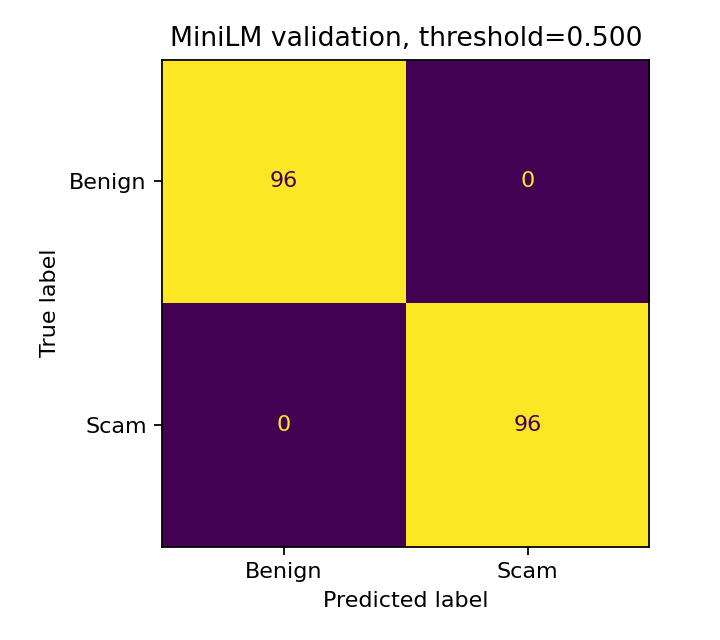

No validation errors to interpret.


In [5]:
summary = run_minilm(DATA_DIR, INPUT_DIR / "fixed_manifest.csv", INPUT_DIR / "reference", OUTPUT_DIR,
                     require_a100=REQUIRE_COLAB_A100)
display(summary)
display(pd.read_csv(OUTPUT_DIR / "wordpiece_lengths.csv").groupby("split").agg(
    n=("dialogue_id", "size"), median_wordpieces=("content_wordpieces", "median"),
    max_wordpieces=("content_wordpieces", "max"), chunked_dialogues=("would_truncate_at_256", "sum")))
display(pd.read_csv(OUTPUT_DIR / "validation_search.csv"))
display(pd.read_csv(OUTPUT_DIR / "validation_by_type.csv"))
display(Image(filename=str(OUTPUT_DIR / "validation_confusion_matrix.png")))
errors = pd.read_csv(OUTPUT_DIR / "validation_errors.csv")
if errors.empty:
    print("No validation errors to interpret.")
else:
    display(errors)


## Frozen incomplete-information evaluation on original validation

Score the first 25/50/75/100% of speaker turns using unchanged classifiers and
thresholds. An early prefix may end before the relevant scam request. These
validation robustness results are not used to retune either model. Challenge-set
prefixes are not scored before independent review and locking.


,model,turn_fraction,threshold,n,scam_support,precision,recall,f1,accuracy,false_positive_rate
0,minilm_logreg,0.25,0.5,192,96,1.0,0.885417,0.939227,0.942708,0.0
1,tfidf_logreg,0.25,0.5,192,96,1.0,1.000000,1.000000,1.000000,0.0
2,minilm_logreg,0.50,0.5,192,96,1.0,0.989583,0.994764,0.994792,0.0
3,tfidf_logreg,0.50,0.5,192,96,1.0,1.000000,1.000000,1.000000,0.0
4,minilm_logreg,0.75,0.5,192,96,1.0,1.000000,1.000000,1.000000,0.0
5,tfidf_logreg,0.75,0.5,192,96,1.0,1.000000,1.000000,1.000000,0.0
6,minilm_logreg,1.00,0.5,192,96,1.0,1.000000,1.000000,1.000000,0.0
7,tfidf_logreg,1.00,0.5,192,96,1.0,1.000000,1.000000,1.000000,0.0


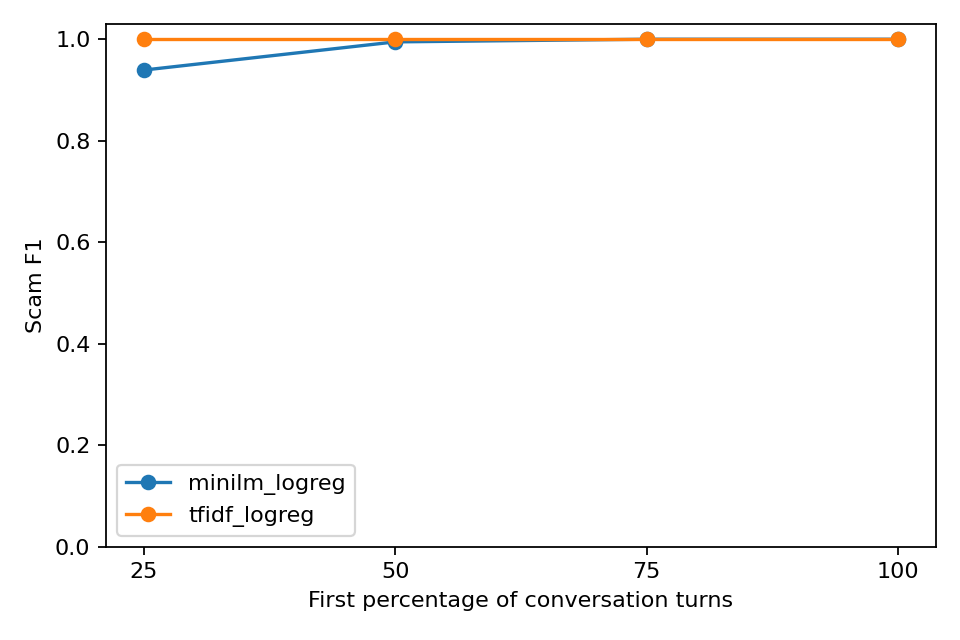

split       fold
train        0      218
             1      217
             2      217
             3      217
             4      217
validation  -1      192
dtype: int64

Challenge scoring is pending independent labels and lock. Official test comparison follows that evaluation.


In [6]:
display(pd.read_csv(OUTPUT_DIR / "validation_prefix_metrics.csv"))
display(Image(filename=str(OUTPUT_DIR / "validation_prefix_performance.png")))
display(pd.read_csv(OUTPUT_DIR / "fusion_scores_train_validation.csv").groupby(["split", "fold"]).size())
print("Challenge scoring is pending independent labels and lock. Official test comparison follows that evaluation.")
assert not summary["challenge_scored"] and not summary["test_evaluated"]


## Recover artifacts

Download the archive, verify all notebook cells and saved hashes, and preserve the
embedding cache for repeated experiments. The independent review packet lives
locally; this runtime has not received its draft transcripts or author labels.


In [7]:
import shutil
assert (OUTPUT_DIR / "minilm_summary.json").exists()
assert (OUTPUT_DIR / "comparison_freeze.json").exists()
archive = shutil.make_archive(str(ROOT / "text_minilm_artifacts"), "zip", OUTPUT_DIR)
print("Artifact archive:", archive)


Artifact archive: /content/text_minilm_artifacts.zip
